# **C16-C17 - Simulación Multiactivo**
## **Simulación de Procesos Financieros**

---

**Autor:** Francisco Uriel Ledezma Chávez  
**Carrera:** Ingeniería Financiera  
**Institución:** ITESO — Universidad Jesuita de Guadalajara  
**Semestre:** 5° — Simulación de Procesos Financieros  
**Fecha de realización:** 2, 4 y 8 de noviembre de 2026

---

**Ejercicio:** simular a un año un capital de 100,000 pesos invertido primero en NVDA, BIMBOA, CEMEX y AZN y después en AAPL, MSFT y NVDA, comparando en cada caso tres esquemas de inversión, para lo cual se estiman el rendimiento y la volatilidad logarítmicos de cada activo y del tipo de cambio sobre tres años de precios, se simulan 10,000 escenarios con el movimiento browniano geométrico, se calculan el número de acciones y el valor final en pesos de cada esquema y se comparan sus distribuciones, suponiendo primero que los factores son independientes y generando después, con la descomposición de Cholesky, escenarios que respetan la correlación observada entre ellos.

Hasta C15 la simulación sirvió para valuar contratos y para reducir el error de esa valuación, mientras que aquí cambia de propósito, ya que deja de estimar un solo número, el precio, para describir la distribución completa del valor de una inversión, y con ello la dispersión deja de ser un error que conviene reducir y se convierte en el objeto mismo del análisis, el riesgo del portafolio, medido como la variabilidad de su valor final y la probabilidad de terminar por debajo del capital.

La pregunta de fondo es cuánto cambia esa medición al abandonar el supuesto de independencia, tanto entre acciones de sectores distintos como entre acciones de un mismo sector, ya que diversificar sólo protege en la medida en que los activos no caigan juntos.

## Índice de contenidos

1. Sección 1 — Datos históricos y cotizaciones de clase
2. Sección 2 — Rendimiento y volatilidad logarítmicos
3. Sección 3 — Simulación del precio a un año
4. Sección 4 — Portafolio A, solo NVDA
5. Sección 5 — Portafolio B, equiponderado
6. Sección 6 — Portafolio C, pesos diversos
7. Sección 7 — Comparación de los tres portafolios
8. Sección 8 — Números correlacionados con la descomposición de Cholesky
9. Sección 9 — Tarea 1: los portafolios de la sección 7 con factores correlacionados
10. Sección 10 — Tarea 2: esquemas sobre AAPL, MSFT y NVDA
11. Sección 11 — Conclusiones

## Importación de bibliotecas

In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(67)

## 1. Datos históricos y cotizaciones de clase

La muestra cubre los tres años que van del 2 de noviembre de 2023 al 2 de noviembre de 2026, con los cierres diarios de NVDA y AZN, que cotizan en dólares en Estados Unidos, de BIMBOA y CEMEX, que cotizan en pesos en la Bolsa Mexicana de Valores, y del tipo de cambio USD/MXN, mientras que la última fila no es un cierre descargado sino las cotizaciones tomadas en clase, que fijan el precio inicial de cada activo.

In [2]:
Capital = 100000
Tickers = ['NVDA', 'BIMBOA.MX', 'CEMEXCPO.MX', 'AZN']
Prices = yf.download(Tickers, start='2023-11-02', end='2026-11-02', progress=False)['Close'][Tickers]
Forex = yf.download(['USDMXN=X'], start='2023-11-02', end='2026-11-02', progress=False)['Close']

# Cotizaciones tomadas en clase el 2 de noviembre; BIMBOA y CEMEX repiten su cierre del 30 de octubre
Prices.loc[pd.Timestamp('2026-11-02'), :] = [202.06, 66.18, 20.23, 186.58]
Forex.loc[pd.Timestamp('2026-11-02'), :] = 18.5657

print("Acciones:", Prices.index[0].date(), "a", Prices.index[-1].date(), "·", len(Prices), "fechas")
print("Cierres por serie:", Prices.count().to_dict(), "· USDMXN:", len(Forex))
pd.concat([Prices, Forex], axis=1).iloc[[0, 1, -2, -1]]

Acciones: 2023-11-02 a 2026-11-02 · 774 fechas
Cierres por serie: {'NVDA': 752, 'BIMBOA.MX': 750, 'CEMEXCPO.MX': 750, 'AZN': 752} · USDMXN: 778


Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,USDMXN=X
Date,,,,,
2023-11-02,43.376453,NaN,NaN,121.751060,17.76235
2023-11-03,44.870987,74.936394,11.458241,121.333710,17.52700
2026-10-30,204.639999,66.180000,20.230000,186.649994,18.85210
2026-11-02,202.060000,66.180000,20.230000,186.580000,18.56570


La tabla de precios reúne 774 fechas, aunque NVDA y AZN tienen 752 cierres y BIMBOA y CEMEX sólo 750, ya que cada bolsa tiene sus propios días inhábiles, como el 2 de noviembre de 2023, fecha en la que las dos emisoras mexicanas aparecen vacías, mientras que el tipo de cambio suma 778 observaciones, y en la última fila BIMBOA y CEMEX repiten su cierre del 30 de octubre, señal de que tampoco cotizaron el día de la clase.

## 2. Rendimiento y volatilidad logarítmicos

Cada activo se resume en dos cifras anualizadas calculadas sobre rendimientos logarítmicos, la media diaria multiplicada por 252 y la desviación estándar multiplicada por $\sqrt{252}$, y como en C14 la media logarítmica estima $\mu - \sigma^2/2$, de modo que la deriva que recibe el movimiento browniano geométrico se recupera sumándole la mitad de la varianza, mientras que los rendimientos se calculan serie por serie, ya que eliminar de golpe las fechas en que falta algún activo descartaría, en cada día inhábil de una bolsa, dos rendimientos válidos de los activos que sí cotizaron.

$$\hat{m}_i = 252\;\overline{\ln\left(S_{i,t}/S_{i,t-1}\right)}, \qquad \hat{\sigma}_i = \sqrt{252}\;s_{\ln,i}, \qquad \hat{\mu}_i = \hat{m}_i + \frac{\hat{\sigma}_i^2}{2}$$

In [3]:
Rendimientos_Logaritmicos = {}
for ticker in Tickers:
    precios = Prices[ticker].dropna()   # cada bolsa tiene sus propios días inhábiles, así que cada serie se limpia por separado
    Rendimientos_Logaritmicos[ticker] = np.log(precios / precios.shift(1)).dropna()
Rendimientos_Logaritmicos = pd.DataFrame(Rendimientos_Logaritmicos)

Mean = Rendimientos_Logaritmicos.mean() * 252
Std = Rendimientos_Logaritmicos.std() * np.sqrt(252)
Deriva = Mean + 0.5 * Std ** 2   # deriva aritmética que recibe el GBM, como en C14

Rendimientos_Forex_Logaritmicos = np.log(Forex / Forex.shift(1)).dropna()
Mean_Forex = Rendimientos_Forex_Logaritmicos.mean().iloc[0] * 252
Std_Forex = Rendimientos_Forex_Logaritmicos.std().iloc[0] * np.sqrt(252)
Deriva_Forex = Mean_Forex + 0.5 * Std_Forex ** 2

Parametros = pd.DataFrame({
    "Rendimientos diarios": Rendimientos_Logaritmicos.count(),
    "Rendimiento logarítmico anual": Mean,
    "Volatilidad anual": Std,
    "Deriva del GBM": Deriva,
})
Parametros.loc["USDMXN"] = [len(Rendimientos_Forex_Logaritmicos), Mean_Forex, Std_Forex, Deriva_Forex]
Parametros.astype({"Rendimientos diarios": int}).round(4)

,Rendimientos diarios,Rendimiento logarítmico anual,Volatilidad anual,Deriva del GBM
NVDA,751,0.5163,0.4654,0.6246
BIMBOA.MX,749,-0.0418,0.2961,0.0020
CEMEXCPO.MX,749,0.1913,0.3267,0.2446
AZN,751,0.1432,0.2484,0.1741
USDMXN,777,0.0143,0.1100,0.0204


NVDA domina la muestra, ya que pasó de 43.38 a 202.06 dólares en tres años, lo cual equivale a un rendimiento logarítmico de 0.5163 anual con la volatilidad más alta, de 0.4654, y a una deriva de 0.6246 una vez corregida, mientras que en el otro extremo BIMBOA tuvo un rendimiento logarítmico negativo de -0.0418 y una deriva de apenas 0.0020, de modo que el modelo espera que su precio se mantenga prácticamente donde está, y CEMEX y AZN quedan en medio, con derivas de 0.2446 y 0.1741.

El tipo de cambio es la serie más estable, con una volatilidad de 0.1100, menos de la mitad que la de cualquier acción, y una deriva de 0.0204 que anticipa una depreciación moderada del peso, de modo que su efecto sobre NVDA y AZN será pequeño frente a la variación de las propias acciones, aunque no nulo, ya que cada escenario de esos dos activos se multiplica por su propio tipo de cambio simulado.

## 3. Simulación del precio a un año

La simulación proyecta un año, $T = 1$, con 10,000 escenarios del precio final de cada activo y del tipo de cambio, generados con la misma expresión del movimiento browniano geométrico de las sesiones anteriores, aunque con la deriva estimada en lugar de la tasa libre de riesgo, ya que aquí no se valúa un contrato sino que se describe la distribución del valor que el portafolio puede alcanzar, y los precios de NVDA y AZN se convierten a pesos escenario por escenario, multiplicando cada precio simulado en dólares por el tipo de cambio simulado en ese mismo escenario.

Los mismos 10,000 escenarios alimentan después a los tres portafolios, de modo que sus diferencias provienen sólo de la forma en que reparten el capital y no del azar de simulaciones distintas.

$$S_{T,i} = S_{0,i}\, e^{\left(\hat{\mu}_i - \frac{\hat{\sigma}_i^2}{2}\right)T + \hat{\sigma}_i\sqrt{T}\,Z_i}, \qquad S^{MXN}_{T,i} = S^{USD}_{T,i}\cdot X_T$$

In [4]:
def Final_Price(S0, Mean, Std, T, M):
    Z = np.random.normal(0, 1, M)
    S_T = S0 * np.exp((Mean - 0.5 * Std**2) * T + Std * np.sqrt(T) * Z)
    return S_T

In [5]:
T = 1
M = 10000
S0 = Prices.iloc[-1]
Forex_0 = Forex.iloc[-1, 0]

St_Forex_Dis = Final_Price(Forex_0, Deriva_Forex, Std_Forex, T, M)
St_dis = pd.DataFrame({ticker: Final_Price(S0[ticker], Deriva[ticker], Std[ticker], T, M) for ticker in Tickers})

# NVDA y AZN cotizan en dólares: cada escenario se convierte a pesos con su propio tipo de cambio simulado
Dolares = ['NVDA', 'AZN']
S0_MXN = S0.copy()
S0_MXN[Dolares] = S0[Dolares] * Forex_0
St_dis_MXN = St_dis.copy()
St_dis_MXN[Dolares] = St_dis[Dolares].mul(St_Forex_Dis, axis=0)

Simulacion = pd.DataFrame({
    "Precio hoy": S0,
    "Valor esperado teórico S0·e^(μT)": S0 * np.exp(Deriva * T),
    "Media simulada": St_dis.mean(),
    "Precio hoy en MXN": S0_MXN,
    "Media simulada en MXN": St_dis_MXN.mean(),
})
Simulacion.loc["USDMXN"] = [Forex_0, Forex_0 * np.exp(Deriva_Forex * T), St_Forex_Dis.mean(), np.nan, np.nan]
Simulacion.round(4)

,Precio hoy,Valor esperado teórico S0·e^(μT),Media simulada,Precio hoy en MXN,Media simulada en MXN
NVDA,202.0600,377.3524,375.9111,3751.3853,7122.3019
BIMBOA.MX,66.1800,66.3153,66.5641,66.1800,66.5641
CEMEXCPO.MX,20.2300,25.8362,25.8207,20.2300,25.8207
AZN,186.5800,222.0589,221.7783,3463.9883,4201.3417
USDMXN,18.5657,18.9483,18.9459,NaN,NaN


Las medias simuladas coinciden con el valor esperado teórico $S_0 e^{\mu T}$ en los cinco casos, como en AZN, que parte de 186.58 dólares y tiene un valor esperado de 222.06 frente a una media simulada de 221.78, o en el tipo de cambio, que pasa de 18.5657 a un valor esperado de 18.9483 frente a 18.9459 simulado, lo cual confirma que los 10,000 escenarios reproducen la deriva que se les asignó, mientras que NVDA ilustra el peso de esa deriva, ya que su precio esperado en un año es de 377.35 dólares, 1.87 veces el actual, y en pesos pasa de 3,751.39 a una media de 7,122.30.

## 4. Portafolio A, solo NVDA

Cada portafolio reparte el capital de 100,000 pesos según sus pesos $\omega_i$, y como sólo pueden comprarse acciones enteras, el número de títulos de cada activo es el cociente entre el monto asignado y su precio inicial en pesos redondeado hacia abajo, de modo que una parte del capital queda sin invertir, el cambio, que no forma parte del valor final, el cual se obtiene en cada escenario sumando el producto del número de acciones por el precio simulado de cada activo.

$$V_{0,i} = \omega_i V_0, \qquad N_i = \left\lfloor \frac{\omega_i V_0}{S_{0,i}} \right\rfloor, \qquad V_T = \sum_i N_i\, S_{T,i}, \qquad \sum_i \omega_i = 100\%$$

In [6]:
def Portafolio(W, Capital, S0_MXN, St_dis_MXN):
    """N_i = ω_i V0 / S0_i redondeado hacia abajo a acciones enteras; V_T = Σ N_i S_T,i en cada escenario, sin el cambio."""
    V0_i = W * Capital
    N_i = np.floor(V0_i / S0_MXN)
    Cambio = Capital - np.sum(N_i * S0_MXN)
    Vt_dis = St_dis_MXN.mul(N_i, axis=1).sum(axis=1).values
    return N_i, Cambio, Vt_dis


def Resumen(N_i, Cambio, Vt_dis):
    Vt = np.mean(Vt_dis)
    print("Acciones compradas:", ", ".join(f"{t} {int(n)}" for t, n in N_i.items()))
    print(f"Invertido: {Capital - Cambio:,.2f} · cambio sin invertir: {Cambio:,.2f}")
    print("Valor Inicial del Portafolio:", f"{Capital:,.2f}")
    print("Valor Final del Portafolio:", f"{Vt:,.2f}")
    print("Rendimiento Final del Portafolio:", f"{(Vt - Capital) / Capital * 100:.2f} %")


def Histograma(distribuciones, titulo, bins=50):
    """distribuciones = {etiqueta: (Vt_dis, color)}; al comparar varias, la transparencia deja ver el traslape."""
    plt.figure(figsize=(10, 6))
    if len(distribuciones) > 1:
        # Mismas clases para todas, hasta el percentil 99 de la más dispersa, para comparar las alturas en una sola escala
        valores = [Vt_dis for Vt_dis, _ in distribuciones.values()]
        bins = np.linspace(min(v.min() for v in valores), max(np.percentile(v, 99) for v in valores), 100)
    for etiqueta, (Vt_dis, color) in distribuciones.items():
        plt.hist(Vt_dis, bins=bins, density=True, alpha=0.6 if len(distribuciones) == 1 else 0.45, color=color, label=etiqueta)
    plt.axvline(Capital, color='black', linestyle='--', label='Capital inicial')
    plt.ticklabel_format(axis='x', style='plain')
    plt.title(titulo)
    plt.xlabel('Valor Final (MXN)')
    plt.ylabel('Densidad')
    plt.legend()
    plt.show()


def Estadisticos_Valor(Vt_dis):
    return {
        "Valor esperado": np.mean(Vt_dis),
        "Rendimiento esperado (%)": (np.mean(Vt_dis) - Capital) / Capital * 100,
        "Desviación estándar": np.std(Vt_dis, ddof=1),
        "Percentil 5": np.percentile(Vt_dis, 5),
        "Mediana": np.median(Vt_dis),
        "Percentil 95": np.percentile(Vt_dis, 95),
        "Probabilidad de terminar bajo el capital (%)": 100 * np.mean(Vt_dis < Capital),
    }

Acciones compradas: NVDA 26, BIMBOA.MX 0, CEMEXCPO.MX 0, AZN 0
Invertido: 97,536.02 · cambio sin invertir: 2,463.98
Valor Inicial del Portafolio: 100,000.00
Valor Final del Portafolio: 185,179.85
Rendimiento Final del Portafolio: 85.18 %


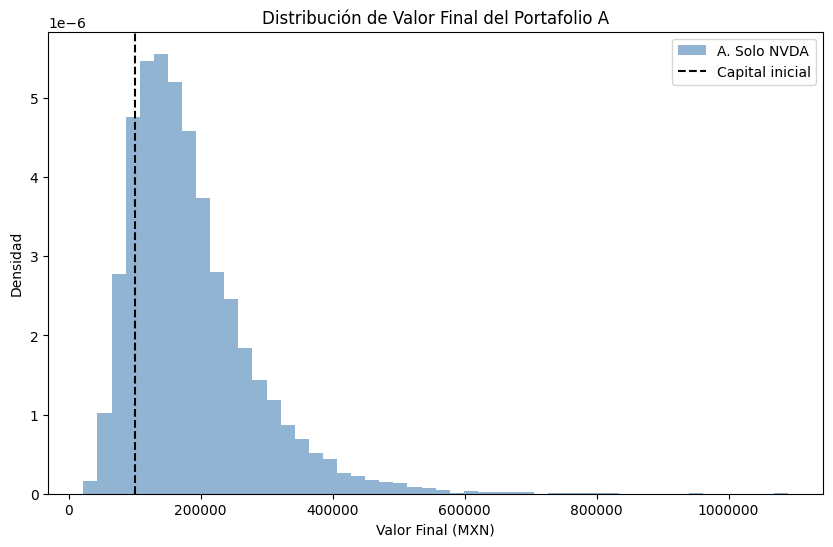

In [7]:
W_A = pd.Series([1, 0, 0, 0], index=Tickers)
N_A, Cambio_A, Vt_A = Portafolio(W_A, Capital, S0_MXN, St_dis_MXN)

Resumen(N_A, Cambio_A, Vt_A)
Histograma({'A. Solo NVDA': (Vt_A, 'SteelBlue')}, 'Distribución de Valor Final del Portafolio A')

El portafolio A invierte todo en NVDA, y como cada acción cuesta 3,751.39 pesos, el capital alcanza para 26 acciones, con 97,536.02 pesos invertidos y 2,463.98 de cambio, mientras que su valor esperado a un año es de unos 185,180 pesos, un rendimiento de 85.18%, cifra que hereda directamente la deriva de 0.6246 de NVDA y que, por lo mismo, depende de que los próximos doce meses repitan el ritmo de los últimos tres.

El histograma muestra la forma característica de un precio lognormal con volatilidad alta, con la mayor parte de la masa a la derecha del capital inicial y una cola derecha que llega cerca del millón de pesos, de modo que unos cuantos escenarios extremos elevan el promedio por encima de lo que obtendría un resultado típico, asimetría que la sección 7 mide al comparar la media con la mediana.

## 5. Portafolio B, equiponderado

Acciones compradas: NVDA 6, BIMBOA.MX 377, CEMEXCPO.MX 1235, AZN 7
Invertido: 96,690.14 · cambio sin invertir: 3,309.86
Valor Inicial del Portafolio: 100,000.00
Valor Final del Portafolio: 129,126.47
Rendimiento Final del Portafolio: 29.13 %


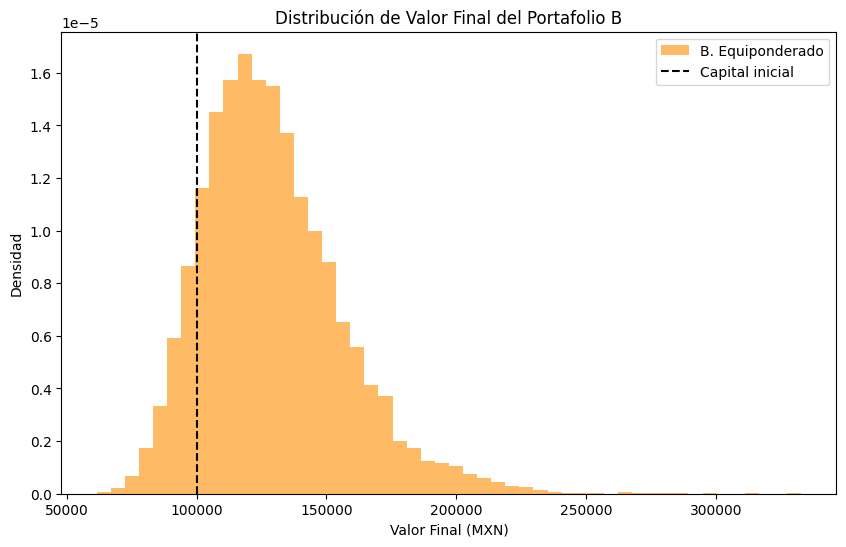

In [8]:
W_B = pd.Series(np.ones(len(Tickers)) / len(Tickers), index=Tickers)
N_B, Cambio_B, Vt_B = Portafolio(W_B, Capital, S0_MXN, St_dis_MXN)

Resumen(N_B, Cambio_B, Vt_B)
Histograma({'B. Equiponderado': (Vt_B, 'DarkOrange')}, 'Distribución de Valor Final del Portafolio B')

El portafolio B asigna 25,000 pesos a cada activo, con lo cual compra 6 acciones de NVDA, 377 de BIMBOA, 1,235 de CEMEX y 7 de AZN, con un cambio de 3,309.86 pesos, y su valor esperado baja a 129,126, un rendimiento de 29.13%, ya que tres cuartas partes del capital pasan a activos cuyas derivas, de 0.0020 a 0.2446, quedan muy por debajo de la de NVDA.

A cambio, el histograma es mucho más compacto y menos asimétrico, con la masa concentrada poco por encima del capital inicial y una cola derecha mucho más corta, porque las variaciones de cuatro activos que se simulan de forma independiente tienden a compensarse entre sí, de modo que un mal año de uno de ellos rara vez coincide con un mal año de todos.

## 6. Portafolio C, pesos diversos

Acciones compradas: NVDA 2, BIMBOA.MX 302, CEMEXCPO.MX 1482, AZN 11
Invertido: 95,573.86 · cambio sin invertir: 4,426.14
Valor Inicial del Portafolio: 100,000.00
Valor Final del Portafolio: 118,828.05
Rendimiento Final del Portafolio: 18.83 %


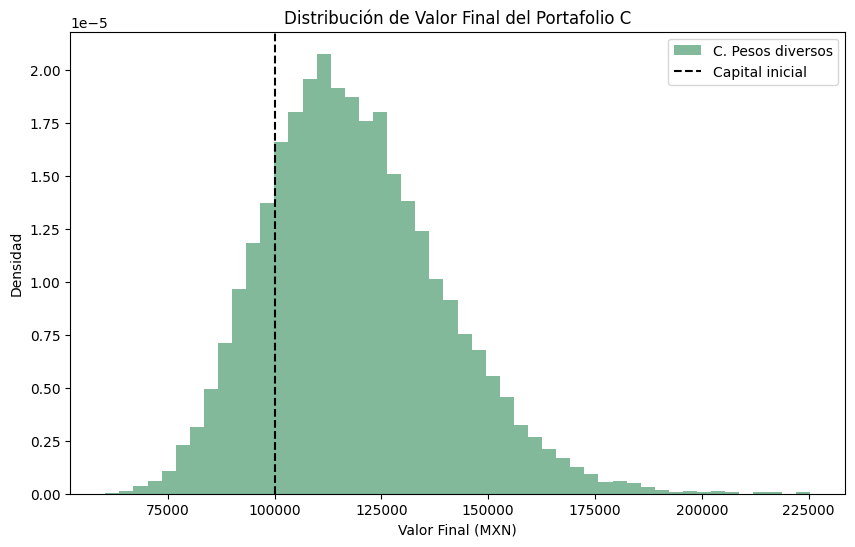

In [9]:
W_C = pd.Series([0.10, 0.20, 0.30, 0.40], index=Tickers)
N_C, Cambio_C, Vt_C = Portafolio(W_C, Capital, S0_MXN, St_dis_MXN)

Resumen(N_C, Cambio_C, Vt_C)
Histograma({'C. Pesos diversos': (Vt_C, 'SeaGreen')}, 'Distribución de Valor Final del Portafolio C')

El portafolio C asigna 10% a NVDA, 20% a BIMBOA, 30% a CEMEX y 40% a AZN, con lo cual compra 2, 302, 1,482 y 11 acciones respectivamente y deja el cambio más alto de los tres, 4,426.14 pesos, ya que las acciones de NVDA y AZN, de 3,751.39 y 3,463.99 pesos, dejan residuos grandes en montos de 10,000 y 40,000 pesos, mientras que su valor esperado es de 118,828, un rendimiento de 18.83%, el menor de los tres, porque reduce NVDA a 10% y lleva el 40% del capital a AZN, cuya deriva de 0.1741 es menos de un tercio de la de NVDA.

El histograma de C es el más estrecho de los tres, aunque su centro queda más cerca del capital inicial, de modo que una parte visible de la distribución cae a la izquierda de la línea punteada, lo cual anticipa que una dispersión menor no implica por sí sola un riesgo de pérdida menor.

## 7. Comparación de los tres portafolios

La comparación reúne primero el número de acciones y el cambio de cada portafolio, después los estadísticos de su valor final, que miden el riesgo con la desviación estándar, los percentiles 5 y 95 y la probabilidad de terminar por debajo del capital, y por último los histogramas superpuestos, en los cuales cada comparación comparte las mismas clases, hasta el percentil 99 de la distribución más dispersa, y la transparencia permite ver dónde se traslapan.

In [10]:
Portafolios = {
    'A. Solo NVDA': (Vt_A, 'SteelBlue'),
    'B. Equiponderado': (Vt_B, 'DarkOrange'),
    'C. Pesos diversos': (Vt_C, 'SeaGreen'),
}

Tabla_N = pd.DataFrame({'A': N_A, 'B': N_B, 'C': N_C}).T.astype(int)
Tabla_N['Cambio'] = [Cambio_A, Cambio_B, Cambio_C]
Tabla_N.round(2)

,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,Cambio
A,26,0,0,0,2463.98
B,6,377,1235,7,3309.86
C,2,302,1482,11,4426.14


El cambio depende de qué tan bien se divide cada monto asignado entre el precio de su acción, y pasa de 2,463.98 pesos en A a 3,309.86 en B y 4,426.14 en C, y como el valor final no lo incluye, C necesita que sus 95,573.86 pesos invertidos crezcan 4.63% sólo para regresar a los 100,000 iniciales, una desventaja de partida que pesa en los estadísticos siguientes.

In [11]:
pd.DataFrame({nombre: Estadisticos_Valor(Vt_dis) for nombre, (Vt_dis, _) in Portafolios.items()}).T.round(2)

,Valor esperado,Rendimiento esperado (%),Desviación estándar,Percentil 5,Mediana,Percentil 95,Probabilidad de terminar bajo el capital (%)
A. Solo NVDA,185179.85,85.18,93340.25,75764.11,165444.62,362671.60,14.39
B. Equiponderado,129126.47,29.13,27093.67,91692.36,125604.71,177122.18,11.58
C. Pesos diversos,118828.05,18.83,20885.62,88112.97,116881.60,155678.67,18.26


La tabla confirma el intercambio entre rendimiento y riesgo, ya que A tiene el valor esperado más alto, 185,180, pero también la desviación estándar más alta, 93,340, y el percentil 5 más bajo, 75,764, lo cual significa que en uno de cada veinte escenarios pierde más de 24% del capital, mientras que B reduce la desviación a 27,094, 71.0% menos, a cambio de bajar el rendimiento esperado de 85.18% a 29.13%.

La asimetría de A se ve en la distancia entre su media y su mediana, ya que el valor esperado supera a la mediana de 165,445 en 19,735 pesos, efecto de la cola derecha que se observó en su histograma, mientras que esa distancia es de 3,522 en B y de 1,946 en C, porque una distribución menos dispersa es también menos asimétrica.

El resultado menos intuitivo es el de C, que tiene la menor desviación estándar, 20,886, y aun así la mayor probabilidad de terminar por debajo del capital, 18.26% frente a 11.58% de B y 14.39% de A, ya que una dispersión baja no protege si el centro de la distribución queda cerca del punto de pérdida, y el de C queda ahí por su deriva menor y por el cambio que no invierte, de modo que B supera a C en valor esperado, mediana, percentil 5 y percentil 95 y sólo pierde frente a él en desviación estándar.

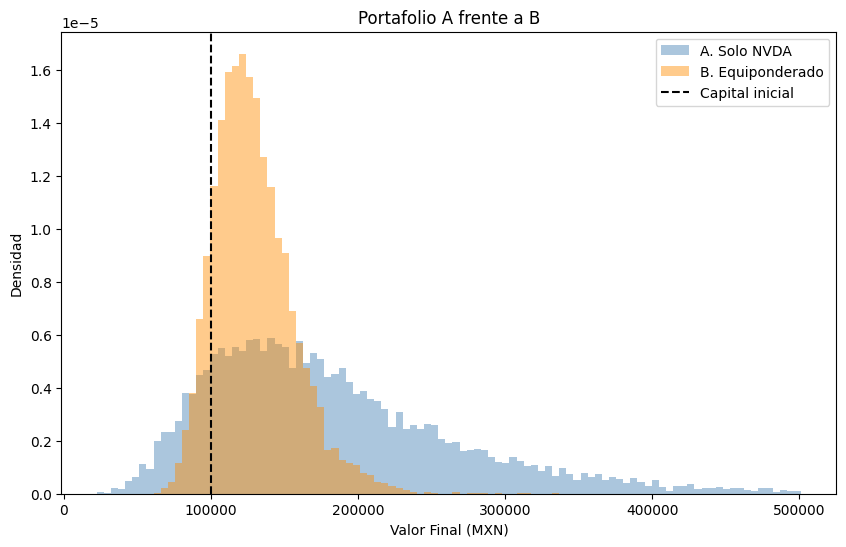

In [12]:
Histograma({k: Portafolios[k] for k in ['A. Solo NVDA', 'B. Equiponderado']}, 'Portafolio A frente a B')

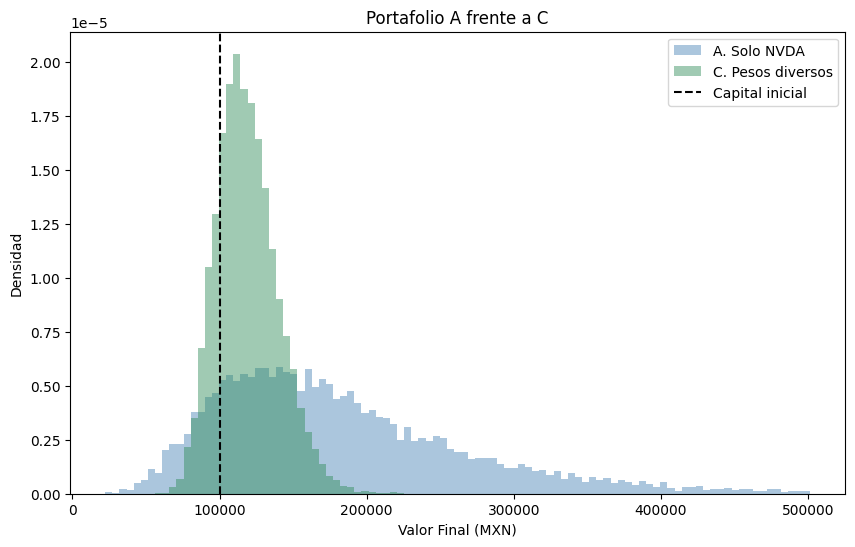

In [13]:
Histograma({k: Portafolios[k] for k in ['A. Solo NVDA', 'C. Pesos diversos']}, 'Portafolio A frente a C')

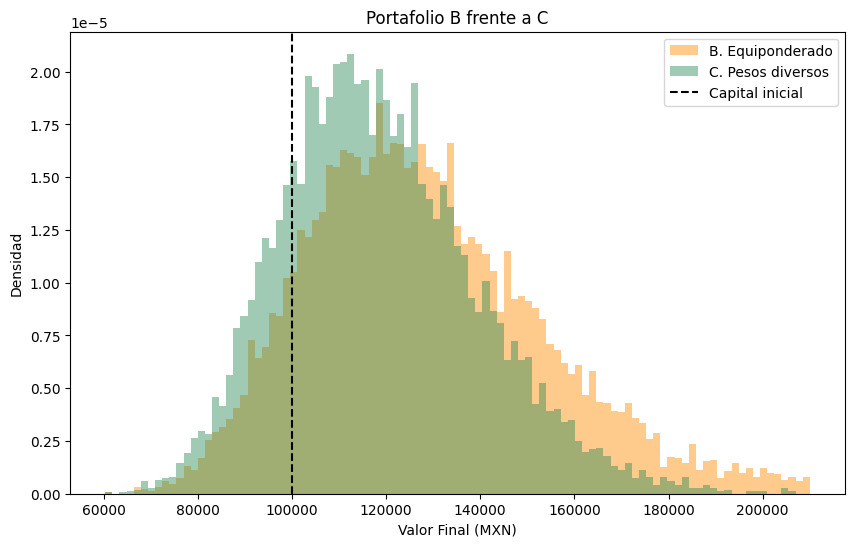

In [14]:
Histograma({k: Portafolios[k] for k in ['B. Equiponderado', 'C. Pesos diversos']}, 'Portafolio B frente a C')

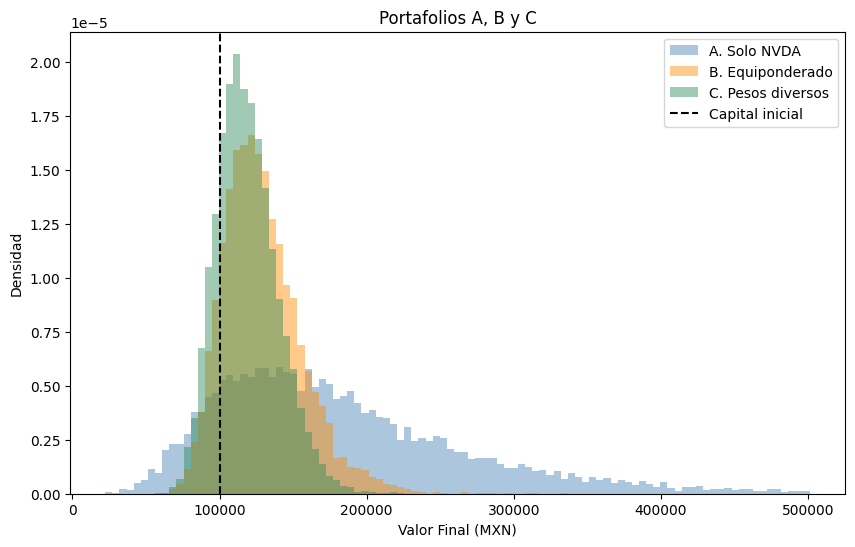

In [15]:
Histograma(Portafolios, 'Portafolios A, B y C')

Los histogramas superpuestos muestran la misma historia en forma visual, ya que frente a A, tanto B como C aparecen como picos altos y estrechos montados sobre la parte izquierda de una distribución mucho más extendida, que es la que concentra las ganancias grandes y también las pérdidas grandes, mientras que B y C se traslapan casi por completo y su diferencia está en el desplazamiento, pues C se ubica a la izquierda de B y deja una fracción mayor de su masa antes de la línea del capital inicial.

La gráfica de los tres portafolios resume la decisión, que no consiste en elegir la distribución menos dispersa sino la que ofrece la mejor combinación entre el valor esperado y la parte de la distribución que cae en pérdida.

## 8. Números correlacionados con la descomposición de Cholesky

Hasta aquí cada activo recibió su propio choque normal, sin relación con los de los demás, y en la siguiente clase ese supuesto se levantó sobre tres acciones del mismo sector, AAPL, MSFT y NVDA, con la descomposición de Cholesky, que escribe una matriz como el producto de una triangular inferior $L$ por su transpuesta y con ello convierte un vector de normales independientes $E$ en otro vector $Z$ cuyos elementos guardan entre sí la relación que describe esa matriz.

$$Z = L\,E, \qquad L\,L^{\top} = \text{matriz que se descompone}$$

In [16]:
Tickers_B = ['AAPL', 'MSFT', 'NVDA']
Prices_B = yf.download(Tickers_B, start='2023-11-02', end='2026-11-02', progress=False)['Close'][Tickers_B]
Rendimientos_B = np.log(Prices_B / Prices_B.shift(1)).dropna()
Covarianza = Rendimientos_B.cov()

print("Cierres:", Prices_B.index[0].date(), "a", Prices_B.index[-1].date(), "·", len(Rendimientos_B), "rendimientos diarios")
Covarianza.round(6)

Cierres: 2023-11-02 a 2026-10-30 · 750 rendimientos diarios


Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,0.000282,0.000092,0.000140
MSFT,0.000092,0.000267,0.000202
NVDA,0.000140,0.000202,0.000861


La matriz que se descompuso en clase fue la covarianza de los rendimientos diarios, y la tabla siguiente compara la desviación de los números que produce con la que resulta al descomponer la matriz de correlación, ya que la fórmula del precio espera en $Z$ una normal estándar y la multiplica ella misma por la volatilidad.

In [17]:
np.random.seed(67)
N_Act = len(Tickers_B)

L = np.linalg.cholesky(Covarianza)
E = np.random.normal(0, 1, size=(N_Act, M))
Z = (0 + L @ E).T

Correlacion = Rendimientos_B.corr()
L_corr = np.linalg.cholesky(Correlacion)
Z_corr = (0 + L_corr @ E).T

print("L de la covarianza = desviación diaria × L de la correlación:", np.allclose(L, np.diag(Rendimientos_B.std()) @ L_corr))

pd.DataFrame({
    "Desviación diaria histórica": Rendimientos_B.std(),
    "Desviación de Z con covarianza": np.std(Z, axis=0, ddof=1),
    "Desviación de Z con correlación": np.std(Z_corr, axis=0, ddof=1),
}).round(4)

L de la covarianza = desviación diaria × L de la correlación: True


,Desviación diaria histórica,Desviación de Z con covarianza,Desviación de Z con correlación
Ticker,,,
AAPL,0.0168,0.0167,0.9948
MSFT,0.0163,0.0163,0.9967
NVDA,0.0293,0.0294,1.0007


Con la covarianza, $Z$ hereda la escala de un solo día, con desviaciones de 0.0167, 0.0163 y 0.0294 que replican las históricas de 0.0168, 0.0163 y 0.0293, de modo que sustituirla en la fórmula del precio aplicaría la volatilidad dos veces y dejaría a cada acción casi sin dispersión, mientras que con la correlación las desviaciones resultan de 0.9948, 0.9967 y 1.0007, y como la $L$ de la covarianza es exactamente la $L$ de la correlación multiplicada por la desviación diaria de cada activo, las dos versiones sólo difieren en esa escala, por lo cual el resto del trabajo descompone la matriz de correlación.

In [18]:
pd.concat({
    "Histórica": Correlacion,
    "Simulada con L de la correlación": pd.DataFrame(np.corrcoef(Z_corr, rowvar=False), index=Tickers_B, columns=Tickers_B),
}).round(4)

AAPL    MSFT    NVDA
                                 Ticker                        
Histórica                        AAPL    1.0000  0.3340  0.2834
                                 MSFT    0.3340  1.0000  0.4217
                                 NVDA    0.2834  0.4217  1.0000
Simulada con L de la correlación AAPL    1.0000  0.3293  0.2946
                                 MSFT    0.3293  1.0000  0.4306
                                 NVDA    0.2946  0.4306  1.0000

La correlación de los números simulados reproduce la histórica, con 0.3293 frente a 0.3340 entre AAPL y MSFT, 0.2946 frente a 0.2834 entre AAPL y NVDA y 0.4306 frente a 0.4217 entre MSFT y NVDA, y esas tres cifras positivas, todas mayores a 0.28, reflejan que las tres empresas responden a los mismos factores de mercado, por lo cual tratarlas como independientes sería un supuesto difícil de sostener.

## 9. Tarea 1: los portafolios de la sección 7 con factores correlacionados

La primera parte de la tarea repite el ejercicio de las secciones 1 a 7 con los mismos precios iniciales, rendimientos, volatilidades y número de acciones, y sólo sustituye el supuesto de independencia por la correlación entre los cinco factores, las cuatro acciones y el tipo de cambio, estimada sobre las fechas en que todos tienen dato, de modo que la diferencia entre ambos casos proviene exclusivamente de cómo se mueven juntos.

In [19]:
def Rendimientos_Factores(Precios, Forex):
    """Rendimientos sobre las fechas comunes, con el tipo de cambio del mismo día y con el del día siguiente."""
    Rend_Precios = np.log(Precios / Precios.shift(1))
    Rend_Forex = np.log(Forex / Forex.shift(1))
    return pd.concat([Rend_Precios, Rend_Forex], axis=1).dropna(), pd.concat([Rend_Precios, Rend_Forex.shift(-1)], axis=1).dropna()


def Correlacion_Forex(Precios, Forex):
    """Correlación de cada activo con USD/MXN: mismo día, día siguiente y suma de cinco días, que casi no depende de la hora de cierre."""
    Mismo_Dia, Dia_Siguiente = Rendimientos_Factores(Precios, Forex)
    Cinco_Dias = Mismo_Dia.rolling(5).sum().dropna()
    return pd.DataFrame({
        "Mismo día": Mismo_Dia.corr()['USDMXN=X'].drop('USDMXN=X'),
        "Día siguiente": Dia_Siguiente.corr()['USDMXN=X'].drop('USDMXN=X'),
        "Cinco días": Cinco_Dias.corr()['USDMXN=X'].drop('USDMXN=X'),
    }).round(4)

In [20]:
Factores_A = Tickers + ['USDMXN=X']
Rend_Mismo_Dia_A, Rend_Alineado_A = Rendimientos_Factores(Prices, Forex)
Corr_Mismo_Dia_A = Rend_Mismo_Dia_A[Factores_A].corr()
Corr_Alineada_A = Rend_Alineado_A[Factores_A].corr()

print(f"Fechas comunes: {len(Rend_Mismo_Dia_A)} con el dólar del mismo día y {len(Rend_Alineado_A)} con el del día siguiente")
Corr_Mismo_Dia_A.round(4)

Fechas comunes: 682 con el dólar del mismo día y 681 con el del día siguiente


Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,USDMXN=X
Ticker,,,,,
NVDA,1.0000,0.0877,0.2426,-0.0017,0.0068
BIMBOA.MX,0.0877,1.0000,0.2113,0.1080,0.0588
CEMEXCPO.MX,0.2426,0.2113,1.0000,0.0976,-0.0222
AZN,-0.0017,0.1080,0.0976,1.0000,-0.0085
USDMXN=X,0.0068,0.0588,-0.0222,-0.0085,1.0000


Las correlaciones entre acciones de sectores distintos son bajas, ya que la mayor es de 0.2426 entre NVDA y CEMEX, le sigue 0.2113 entre BIMBOA y CEMEX, y NVDA y AZN prácticamente no se relacionan, con -0.0017, de modo que la independencia supuesta en clase es una aproximación razonable aunque no exacta, mientras que la columna del tipo de cambio resulta sospechosa, con valores de -0.0222 a 0.0588, ya que cabría esperar que el dólar se fortaleciera frente al peso en los días en que las acciones caen.

In [21]:
Correlacion_Forex(Prices, Forex)

,Mismo día,Día siguiente,Cinco días
Ticker,,,
NVDA,0.0068,-0.2501,-0.2239
BIMBOA.MX,0.0588,-0.1404,0.0347
CEMEXCPO.MX,-0.0222,-0.2104,-0.1451
AZN,-0.0085,-0.0888,-0.0538


La causa es de calendario y no económica, ya que Yahoo Finance etiqueta con la fecha $d$ la barra del tipo de cambio que cierra poco antes de la medianoche UTC del día anterior, de modo que el rendimiento del dólar fechado en $d$ refleja en realidad la sesión de Nueva York de $d-1$, y la tabla lo confirma, pues frente al dólar del día siguiente la correlación pasa de 0.0068 a -0.2501 en NVDA y de -0.0222 a -0.2104 en CEMEX, mientras que la suma de rendimientos de cinco días, que casi no depende de la hora de cierre, también resulta negativa en NVDA, con -0.2239, en CEMEX, con -0.1451, y en AZN, con -0.0538, y sólo en BIMBOA se queda en 0.0347, por lo cual el análisis usa la correlación con el dólar alineado un día y conserva la del mismo día como variante.

In [22]:
Corr_Alineada_A.round(4)

Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,USDMXN=X
Ticker,,,,,
NVDA,1.0000,0.0877,0.2426,-0.0017,-0.2501
BIMBOA.MX,0.0877,1.0000,0.2113,0.1080,-0.1404
CEMEXCPO.MX,0.2426,0.2113,1.0000,0.0976,-0.2104
AZN,-0.0017,0.1080,0.0976,1.0000,-0.0888
USDMXN=X,-0.2501,-0.1404,-0.2104,-0.0888,1.0000


La matriz alineada conserva las correlaciones entre acciones y cambia sólo la última columna, que ahora tiene el signo esperado, ya que cuando las acciones suben el peso tiende a apreciarse, y ese signo tiene consecuencias para un inversionista en pesos, pues en las posiciones en dólares el tipo de cambio actúa como una cobertura parcial de la acción.

Los choques independientes son exactamente los de la sección 3, que se recuperan reiniciando la semilla, y los correlacionados se obtienen aplicando a esos mismos choques la $L$ de la matriz de correlación, de modo que ambos casos comparten el azar y sólo difieren en la relación entre factores.

In [23]:
np.random.seed(67)
E_A = np.random.normal(0, 1, size=(5, M))   # en la sección 3 la primera fila fue USD/MXN y las otras cuatro, los activos
Z_ind_A = np.vstack([E_A[1:], E_A[0]]).T    # mismo orden que Factores_A: los activos y al final USD/MXN

Z_corr_A = (0 + np.linalg.cholesky(Corr_Alineada_A) @ Z_ind_A.T).T
Z_mismo_dia_A = (0 + np.linalg.cholesky(Corr_Mismo_Dia_A) @ Z_ind_A.T).T

pd.DataFrame(np.corrcoef(Z_corr_A, rowvar=False), index=Factores_A, columns=Factores_A).round(4)

,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,USDMXN=X
NVDA,1.0000,0.0959,0.2345,-0.0064,-0.2551
BIMBOA.MX,0.0959,1.0000,0.2133,0.1215,-0.1290
CEMEXCPO.MX,0.2345,0.2133,1.0000,0.1033,-0.1970
AZN,-0.0064,0.1215,0.1033,1.0000,-0.0888
USDMXN=X,-0.2551,-0.1290,-0.1970,-0.0888,1.0000


La correlación de los choques simulados reproduce la matriz estimada, con 0.2345 frente a 0.2426 entre NVDA y CEMEX y -0.2551 frente a -0.2501 entre NVDA y el tipo de cambio.

In [24]:
def Final_Price_Z(S0, Mean, Std, T, Z):
    """Igual que Final_Price, pero recibe los choques en lugar de generarlos, para poder correlacionarlos."""
    return S0 * np.exp((Mean - 0.5 * Std**2) * T + Std * np.sqrt(T) * Z)


def Escenarios_MXN(Z, Factores, S0_F, Deriva_F, Std_F, Dolares):
    """Precios finales en pesos para unos choques Z de forma (M, factores)."""
    St = pd.DataFrame({f: Final_Price_Z(S0_F[f], Deriva_F[f], Std_F[f], T, Z[:, k]) for k, f in enumerate(Factores)})
    St[Dolares] = St[Dolares].mul(St['USDMXN=X'], axis=0)
    return St.drop(columns='USDMXN=X')


def Comparacion(Valores):
    """Valores = {caso: {variante: Vt_dis}}; una fila por caso y variante."""
    return pd.DataFrame({(caso, variante): Estadisticos_Valor(Vt) for caso, variantes in Valores.items()
                         for variante, Vt in variantes.items()}).T.round(2)

In [25]:
S0_F_A = pd.concat([S0, pd.Series({'USDMXN=X': Forex_0})])
Deriva_F_A = pd.concat([Deriva, pd.Series({'USDMXN=X': Deriva_Forex})])
Std_F_A = pd.concat([Std, pd.Series({'USDMXN=X': Std_Forex})])

Escenarios_A = {
    'Independiente': Escenarios_MXN(Z_ind_A, Factores_A, S0_F_A, Deriva_F_A, Std_F_A, Dolares),
    'Correlacionado': Escenarios_MXN(Z_corr_A, Factores_A, S0_F_A, Deriva_F_A, Std_F_A, Dolares),
    'Correlacionado, dólar del mismo día': Escenarios_MXN(Z_mismo_dia_A, Factores_A, S0_F_A, Deriva_F_A, Std_F_A, Dolares),
}
Casos_A = {'Caso 1. Solo NVDA': W_A, 'Caso 2. Equiponderado': W_B, 'Caso 3. Pesos diversos': W_C}
Valores_A = {caso: {variante: Portafolio(W, Capital, S0_MXN, Esc)[2] for variante, Esc in Escenarios_A.items()}
             for caso, W in Casos_A.items()}

print("El caso independiente reproduce los portafolios de la sección 7:",
      all(np.allclose(Valores_A[caso]['Independiente'], Vt) for caso, Vt in zip(Casos_A, (Vt_A, Vt_B, Vt_C))))

El caso independiente reproduce los portafolios de la sección 7: True


La comprobación anterior confirma que el caso independiente coincide escenario por escenario con los portafolios de la sección 7, y a partir de aquí los tres esquemas de inversión se identifican como casos 1, 2 y 3, que corresponden a los portafolios A, B y C en ese orden.

### Caso 1: solo NVDA

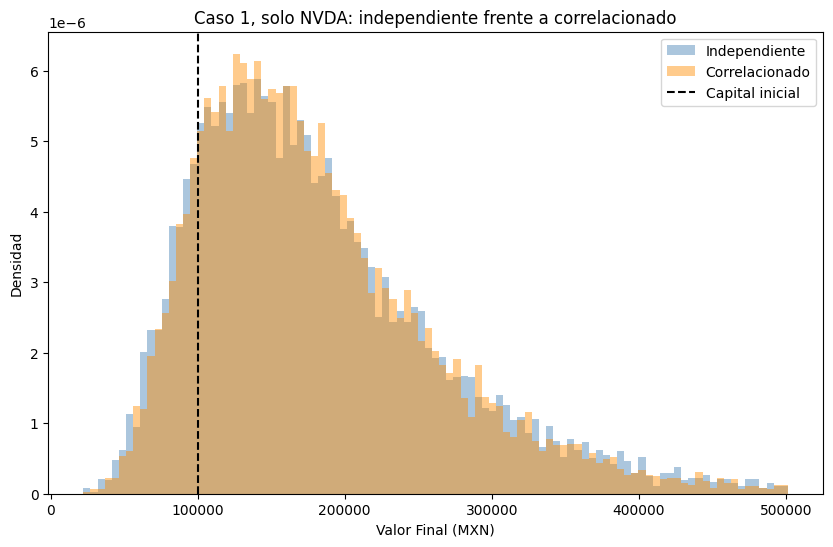

In [26]:
Histograma({'Independiente': (Valores_A['Caso 1. Solo NVDA']['Independiente'], 'SteelBlue'),
            'Correlacionado': (Valores_A['Caso 1. Solo NVDA']['Correlacionado'], 'DarkOrange')},
           'Caso 1, solo NVDA: independiente frente a correlacionado')

En el caso 1 las dos distribuciones se superponen casi por completo, aunque la correlacionada se cierra ligeramente en la cola derecha, ya que la desviación estándar baja de 93,340 a 86,358 y el percentil 95 de 362,672 a 347,100, y la razón es que con una sola acción no hay correlación entre acciones que pueda actuar, de modo que el único vínculo que queda es el de NVDA con el tipo de cambio, de -0.2501, por lo cual el dólar compensa una parte de los movimientos de la acción al convertirla a pesos.

### Caso 2: equiponderado

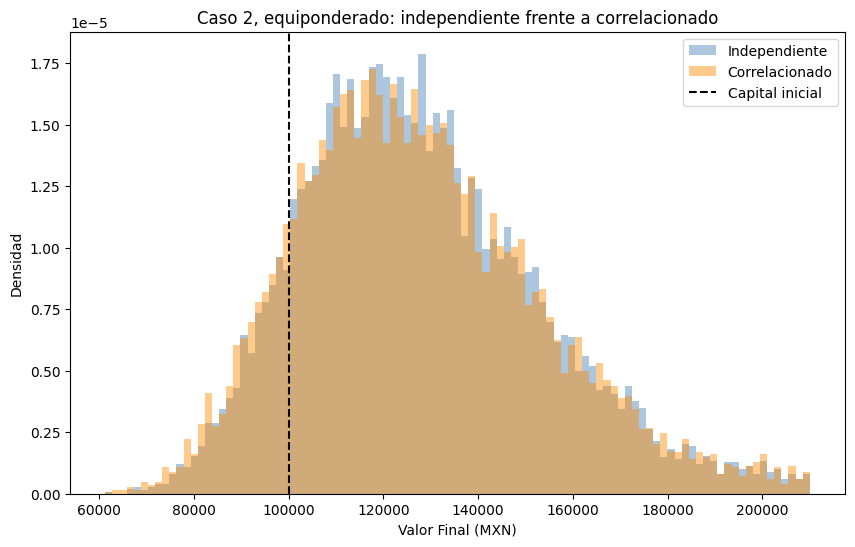

In [27]:
Histograma({'Independiente': (Valores_A['Caso 2. Equiponderado']['Independiente'], 'SteelBlue'),
            'Correlacionado': (Valores_A['Caso 2. Equiponderado']['Correlacionado'], 'DarkOrange')},
           'Caso 2, equiponderado: independiente frente a correlacionado')

En el caso 2 la forma general se mantiene, aunque la distribución correlacionada deja un poco más de masa a la izquierda del capital inicial, con un percentil 5 que baja de 91,692 a 90,235, y el efecto es pequeño porque dos fuerzas se oponen, ya que la correlación positiva entre acciones quita diversificación mientras que la correlación negativa con el dólar amortigua las posiciones en dólares de NVDA y AZN.

### Caso 3: pesos diversos

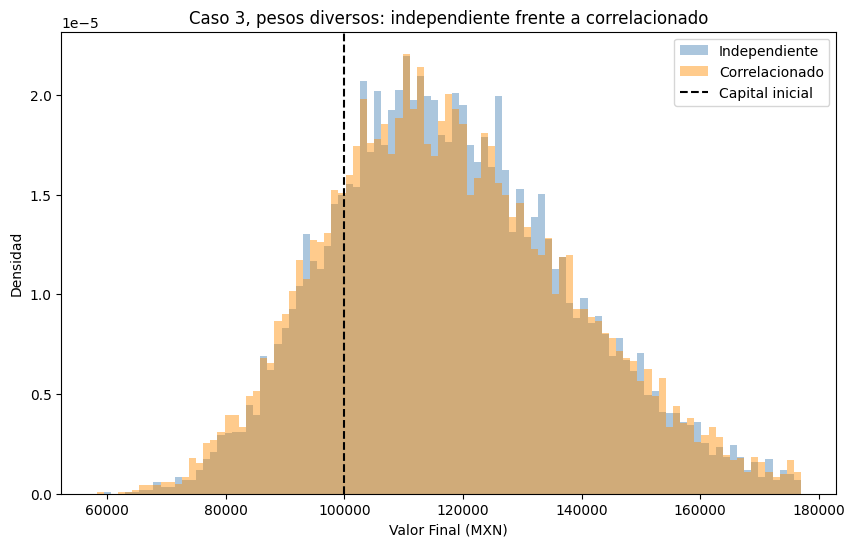

In [28]:
Histograma({'Independiente': (Valores_A['Caso 3. Pesos diversos']['Independiente'], 'SteelBlue'),
            'Correlacionado': (Valores_A['Caso 3. Pesos diversos']['Correlacionado'], 'DarkOrange')},
           'Caso 3, pesos diversos: independiente frente a correlacionado')

En el caso 3 ocurre lo mismo con mayor claridad, ya que la desviación estándar sube de 20,886 a 21,768 y el percentil 5 baja de 88,113 a 86,656, porque la mitad del capital está en BIMBOA y CEMEX, que cotizan en pesos y no reciben la compensación del tipo de cambio, mientras que la correlación de 0.2113 entre ellas sí les resta diversificación.

### Comparación de indicadores

In [29]:
Comparacion(Valores_A)

Valor esperado  \
Caso 1. Solo NVDA      Independiente                             185179.85   
                       Correlacionado                            182860.74   
                       Correlacionado, dólar del mismo día       185272.84   
Caso 2. Equiponderado  Independiente                             129126.47   
                       Correlacionado                            128542.81   
                       Correlacionado, dólar del mismo día       129166.51   
Caso 3. Pesos diversos Independiente                             118828.05   
                       Correlacionado                            118572.52   
                       Correlacionado, dólar del mismo día       118863.44   

                                                            Rendimiento esperado (%)  \
Caso 1. Solo NVDA      Independiente                                           85.18   
                       Correlacionado                                          82.86   
                       Correlacionado, dólar del mismo día                     85.27   
Caso 2. Equiponderado  Independiente                                           29.13   
                       Correlacionado                                          28.54   
                       Correlacionado, dólar del mismo día                     29.17   
Caso 3. Pesos diversos Independiente                                           18.83   
                       Correlacionado                                          18.57   
                       Correlacionado, dólar del mismo día                     18.86   

                                                            Desviación estándar  \
Caso 1. Solo NVDA      Independiente                                   93340.25   
                       Correlacionado                                  86357.98   
                       Correlacionado, dólar del mismo día             93542.26   
Caso 2. Equiponderado  Independiente                                   27093.67   
                       Correlacionado                                  27551.44   
                       Correlacionado, dólar del mismo día             30446.48   
Caso 3. Pesos diversos Independiente                                   20885.62   
                       Correlacionado                                  21768.47   
                       Correlacionado, dólar del mismo día             23669.55   

                                                            Percentil 5  \
Caso 1. Solo NVDA      Independiente                           75764.11   
                       Correlacionado                          79323.53   
                       Correlacionado, dólar del mismo día     75508.12   
Caso 2. Equiponderado  Independiente                           91692.36   
                       Correlacionado                          90234.99   
                       Correlacionado, dólar del mismo día     87538.54   
Caso 3. Pesos diversos Independiente                           88112.97   
                       Correlacionado                          86656.05   
                       Correlacionado, dólar del mismo día     84493.55   

                                                              Mediana  \
Caso 1. Solo NVDA      Independiente                        165444.62   
                       Correlacionado                       165155.54   
                       Correlacionado, dólar del mismo día  165429.63   
Caso 2. Equiponderado  Independiente                        125604.71   
                       Correlacionado                       125182.42   
                       Correlacionado, dólar del mismo día  125152.39   
Caso 3. Pesos diversos Independiente                        116881.60   
                       Correlacionado                       116557.52   
                       Correlacionado, dólar del mismo día  116373.03   

                                                            Percentil 95  \
Caso 1. S

La tabla confirma que la correlación casi no mueve el centro de la distribución y sí su dispersión, ya que el valor esperado sólo cambia por el vínculo entre las acciones en dólares y el tipo de cambio, de 185,180 a 182,861 en el caso 1, de 129,126 a 128,543 en el caso 2 y de 118,828 a 118,573 en el caso 3, mientras que la desviación estándar baja 7.5% en el caso 1 y sube 1.7% en el caso 2 y 4.2% en el caso 3.

La probabilidad de terminar por debajo del capital resume el efecto sobre el inversionista, ya que en los portafolios diversificados sube de 11.58% a 13.18% en el caso 2 y de 18.26% a 19.75% en el caso 3, mientras que en el caso 1 baja de 14.39% a 12.90%, de modo que el orden entre los portafolios cambia, pues con independencia el caso 2 era claramente el de menor probabilidad de pérdida y con correlación queda prácticamente empatado con el caso 1, aunque conserva el percentil 5 más alto, de 90,235, frente a 79,324 y 86,656.

La variante con el dólar del mismo día aísla la correlación entre acciones, ya que ahí el vínculo con el tipo de cambio es casi nulo, y muestra cuánto se subestimaría el riesgo al omitirla, con desviaciones de 30,446 en el caso 2 y 23,670 en el caso 3, 12.4% y 13.3% por encima del caso independiente, y probabilidades de pérdida de 15.40% y 21.85%, mientras que el caso 1 prácticamente no se mueve, con 93,542 frente a 93,340, lo cual confirma que la correlación entre acciones sólo actúa cuando el portafolio tiene más de una y que la cobertura del dólar devuelve una parte del riesgo añadido.

## 10. Tarea 2: esquemas sobre AAPL, MSFT y NVDA

La segunda parte aplica el mismo procedimiento a AAPL, MSFT y NVDA, con 100,000 pesos y los tres esquemas indicados en la tarea, de modo que los parámetros se calculan serie por serie como en la sección 2, mientras que el precio inicial es el último cierre común, el 30 de octubre de 2026, para las tres acciones y el tipo de cambio, ya que de AAPL y MSFT no se tomó cotización en clase.

In [30]:
Mean_B = Rendimientos_B.mean() * 252
Std_B = Rendimientos_B.std() * np.sqrt(252)
Deriva_B = Mean_B + 0.5 * Std_B ** 2

Factores_B = Tickers_B + ['USDMXN=X']
Fecha_Inicial_B = Prices_B.index[-1]   # último cierre común: las tres acciones y el dólar a la misma fecha
Forex_B0 = Forex['USDMXN=X'].loc[Fecha_Inicial_B]

S0_F_B = pd.concat([Prices_B.iloc[-1], pd.Series({'USDMXN=X': Forex_B0})])
Deriva_F_B = pd.concat([Deriva_B, pd.Series({'USDMXN=X': Deriva_Forex})])
Std_F_B = pd.concat([Std_B, pd.Series({'USDMXN=X': Std_Forex})])
S0_MXN_B = S0_F_B[Tickers_B] * Forex_B0

print("Fecha inicial:", Fecha_Inicial_B.date())
pd.DataFrame({
    "Precio inicial": S0_F_B,
    "Precio inicial en MXN": S0_MXN_B,
    "Rendimiento logarítmico anual": pd.concat([Mean_B, pd.Series({'USDMXN=X': Mean_Forex})]),
    "Volatilidad anual": Std_F_B,
    "Deriva del GBM": Deriva_F_B,
}).round(4)

Fecha inicial: 2026-10-30


,Precio inicial,Precio inicial en MXN,Rendimiento logarítmico anual,Volatilidad anual,Deriva del GBM
AAPL,344.6300,6496.9994,0.2273,0.2668,0.2629
MSFT,521.9100,9839.0992,0.1436,0.2593,0.1773
NVDA,204.6400,3857.8938,0.5212,0.4657,0.6297
USDMXN=X,18.8521,NaN,0.0143,0.1100,0.0204


Las tres acciones cotizan en dólares, de modo que todas las posiciones se convierten a pesos con el tipo de cambio simulado, y NVDA conserva el perfil de mayor deriva y volatilidad, con 0.6297 y 0.4657, por encima de AAPL, con 0.2629 y 0.2668, y de MSFT, con 0.1773 y 0.2593, mientras que su deriva difiere ligeramente de los 0.6246 de la sección 2 porque esta muestra termina en el último cierre y no incluye la cotización de clase.

In [31]:
Rend_Mismo_Dia_B, Rend_Alineado_B = Rendimientos_Factores(Prices_B, Forex)
Corr_Mismo_Dia_B = Rend_Mismo_Dia_B[Factores_B].corr()
Corr_Alineada_B = Rend_Alineado_B[Factores_B].corr()

print(f"Fechas comunes: {len(Rend_Mismo_Dia_B)} con el dólar del mismo día y {len(Rend_Alineado_B)} con el del día siguiente")
Correlacion_Forex(Prices_B, Forex)

Fechas comunes: 749 con el dólar del mismo día y 749 con el del día siguiente


,Mismo día,Día siguiente,Cinco días
Ticker,,,
AAPL,0.0047,-0.1439,-0.0946
MSFT,-0.0214,-0.1817,-0.1649
NVDA,-0.0103,-0.2084,-0.1943


In [32]:
Corr_Alineada_B.round(4)

Ticker,AAPL,MSFT,NVDA,USDMXN=X
Ticker,,,,
AAPL,1.0000,0.3324,0.2815,-0.1439
MSFT,0.3324,1.0000,0.4198,-0.1817
NVDA,0.2815,0.4198,1.0000,-0.2084
USDMXN=X,-0.1439,-0.1817,-0.2084,1.0000


El mismo desfase del tipo de cambio aparece aquí, ya que frente al dólar del día siguiente la correlación pasa de valores cercanos a cero a -0.1439 en AAPL, -0.1817 en MSFT y -0.2084 en NVDA, y la matriz alineada mantiene entre las acciones correlaciones de 0.2815 a 0.4198, todas superiores a la mayor de la sección 9, de 0.2426, lo cual anticipa que en este portafolio la diversificación vale menos.

In [33]:
np.random.seed(67)
E_B = np.random.normal(0, 1, size=(4, M))
Z_ind_B = E_B.T

Z_corr_B = (0 + np.linalg.cholesky(Corr_Alineada_B) @ E_B).T
Z_mismo_dia_B = (0 + np.linalg.cholesky(Corr_Mismo_Dia_B) @ E_B).T

Escenarios_B = {
    'Independiente': Escenarios_MXN(Z_ind_B, Factores_B, S0_F_B, Deriva_F_B, Std_F_B, Tickers_B),
    'Correlacionado': Escenarios_MXN(Z_corr_B, Factores_B, S0_F_B, Deriva_F_B, Std_F_B, Tickers_B),
    'Correlacionado, dólar del mismo día': Escenarios_MXN(Z_mismo_dia_B, Factores_B, S0_F_B, Deriva_F_B, Std_F_B, Tickers_B),
}

In [34]:
Casos_B = {
    'Caso 1. [1, 0, 0]': pd.Series([1, 0, 0], index=Tickers_B),
    'Caso 2. [0.33, 0.33, 0.34]': pd.Series([0.33, 0.33, 0.34], index=Tickers_B),
    'Caso 3. [0.2, 0.2, 0.6]': pd.Series([0.2, 0.2, 0.6], index=Tickers_B),
}

N_Casos_B = {}
Cambios_B = []
Valores_B = {}
for caso, W in Casos_B.items():
    N_i, Cambio, _ = Portafolio(W, Capital, S0_MXN_B, Escenarios_B['Independiente'])
    N_Casos_B[caso] = N_i
    Cambios_B.append(Cambio)
    Valores_B[caso] = {variante: Portafolio(W, Capital, S0_MXN_B, Esc)[2] for variante, Esc in Escenarios_B.items()}

Tabla_N_B = pd.DataFrame(N_Casos_B).T.astype(int)
Tabla_N_B['Cambio'] = Cambios_B
Tabla_N_B.round(2)

,AAPL,MSFT,NVDA,Cambio
"Caso 1. [1, 0, 0]",15,0,0,2545.01
"Caso 2. [0.33, 0.33, 0.34]",5,3,8,7134.55
"Caso 3. [0.2, 0.2, 0.6]",3,2,15,2962.40


Con acciones que cuestan entre 3,857.89 y 9,839.10 pesos, comprar títulos enteros deja residuos importantes, ya que el caso 1 compra 15 acciones de AAPL con un cambio de 2,545.01 pesos, el caso 3 compra 3, 2 y 15 acciones con un cambio de 2,962.40 y el caso 2, cuyos montos de 33,000 pesos no se dividen bien entre los precios de AAPL y MSFT, compra 5, 3 y 8 acciones y deja sin invertir 7,134.55 pesos, 7.13% del capital, diferencia que pesa en su probabilidad de terminar por debajo de los 100,000 iniciales.

### Caso 1: [1, 0, 0]

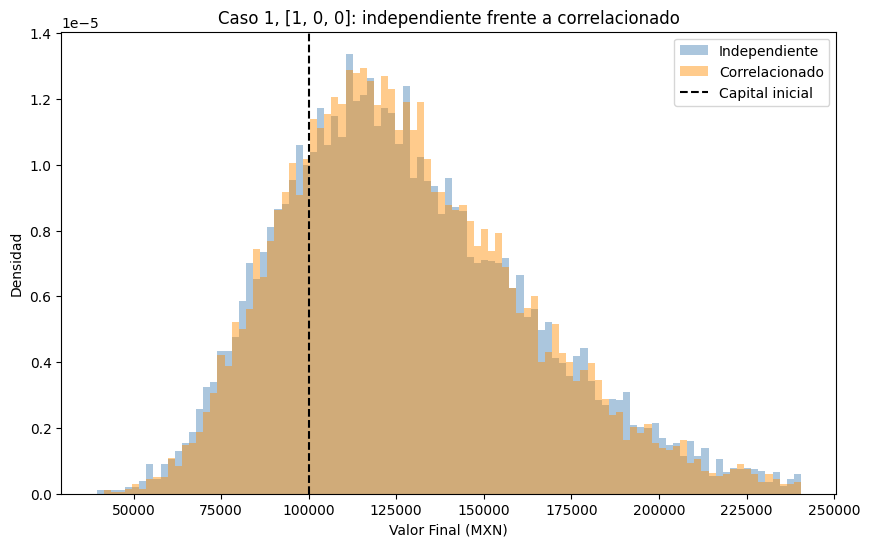

In [35]:
Histograma({'Independiente': (Valores_B['Caso 1. [1, 0, 0]']['Independiente'], 'SteelBlue'),
            'Correlacionado': (Valores_B['Caso 1. [1, 0, 0]']['Correlacionado'], 'DarkOrange')},
           'Caso 1, [1, 0, 0]: independiente frente a correlacionado')

El caso 1 concentra todo en AAPL y repite lo visto con NVDA, ya que las dos distribuciones casi coinciden y la correlacionada se cierra un poco en la cola derecha, con una desviación que baja de 37,954 a 35,746, porque el único vínculo disponible es el de AAPL con el tipo de cambio.

### Caso 2: [0.33, 0.33, 0.34]

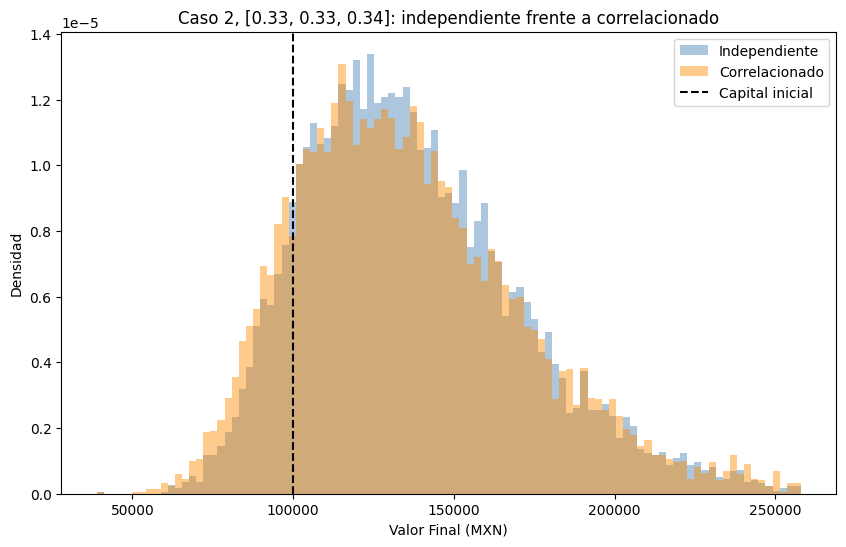

In [36]:
Histograma({'Independiente': (Valores_B['Caso 2. [0.33, 0.33, 0.34]']['Independiente'], 'SteelBlue'),
            'Correlacionado': (Valores_B['Caso 2. [0.33, 0.33, 0.34]']['Correlacionado'], 'DarkOrange')},
           'Caso 2, [0.33, 0.33, 0.34]: independiente frente a correlacionado')

En el caso 2 el efecto se nota más, ya que la distribución correlacionada deja más masa a la izquierda del capital inicial, con un percentil 5 que baja de 90,067 a 85,954, y es el caso más sensible a la correlación porque reparte casi por igual entre tres acciones del mismo sector, de modo que las caídas tienden a coincidir.

### Caso 3: [0.2, 0.2, 0.6]

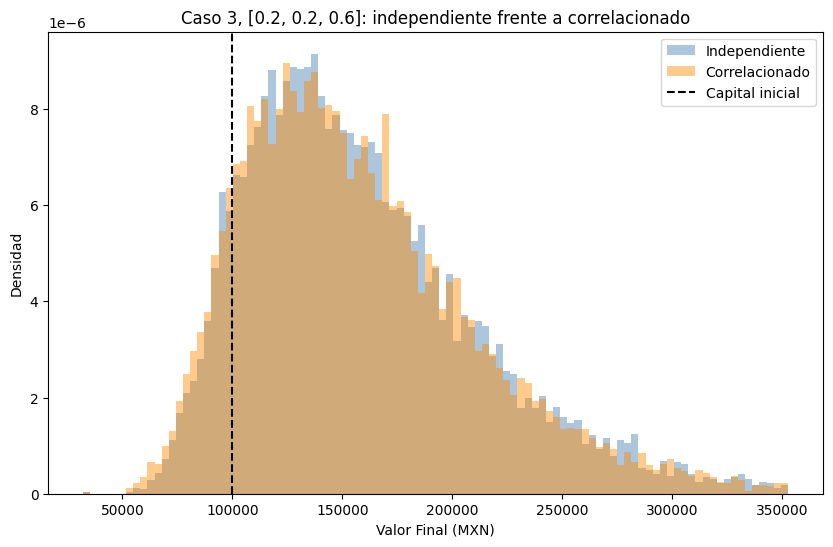

In [37]:
Histograma({'Independiente': (Valores_B['Caso 3. [0.2, 0.2, 0.6]']['Independiente'], 'SteelBlue'),
            'Correlacionado': (Valores_B['Caso 3. [0.2, 0.2, 0.6]']['Correlacionado'], 'DarkOrange')},
           'Caso 3, [0.2, 0.2, 0.6]: independiente frente a correlacionado')

En el caso 3 el 60% en NVDA conserva una cola derecha larga y la correlación apenas altera la dispersión total, con una desviación que pasa de 58,983 a 58,152, ya que el aumento por la correlación entre acciones y la reducción por la correlación con el dólar casi se compensan, aunque la cola izquierda sí empeora, con un percentil 5 que baja de 90,626 a 87,629.

### Comparación de indicadores

In [38]:
Comparacion(Valores_B)

Valor esperado  \
Caso 1. [1, 0, 0]          Independiente                             129289.21   
                           Correlacionado                            128731.63   
                           Correlacionado, dólar del mismo día       129308.85   
Caso 2. [0.33, 0.33, 0.34] Independiente                             138418.68   
                           Correlacionado                            137373.42   
                           Correlacionado, dólar del mismo día       138343.30   
Caso 3. [0.2, 0.2, 0.6]    Independiente                             161230.84   
                           Correlacionado                            159731.32   
                           Correlacionado, dólar del mismo día       161101.91   

                                                                Rendimiento esperado (%)  \
Caso 1. [1, 0, 0]          Independiente                                           29.29   
                           Correlacionado                                          28.73   
                           Correlacionado, dólar del mismo día                     29.31   
Caso 2. [0.33, 0.33, 0.34] Independiente                                           38.42   
                           Correlacionado                                          37.37   
                           Correlacionado, dólar del mismo día                     38.34   
Caso 3. [0.2, 0.2, 0.6]    Independiente                                           61.23   
                           Correlacionado                                          59.73   
                           Correlacionado, dólar del mismo día                     61.10   

                                                                Desviación estándar  \
Caso 1. [1, 0, 0]          Independiente                                   37953.76   
                           Correlacionado                                  35745.71   
                           Correlacionado, dólar del mismo día             38025.76   
Caso 2. [0.33, 0.33, 0.34] Independiente                                   36697.55   
                           Correlacionado                                  38568.24   
                           Correlacionado, dólar del mismo día             42478.99   
Caso 3. [0.2, 0.2, 0.6]    Independiente                                   58982.67   
                           Correlacionado                                  58151.52   
                           Correlacionado, dólar del mismo día             62894.37   

                                                                Percentil 5  \
Caso 1. [1, 0, 0]          Independiente                           76956.23   
                           Correlacionado                          78963.93   
                           Correlacionado, dólar del mismo día     76844.88   
Caso 2. [0.33, 0.33, 0.34] Independiente                           90067.28   
                           Correlacionado                          85953.81   
                           Correlacionado, dólar del mismo día     82739.17   
Caso 3. [0.2, 0.2, 0.6]    Independiente                           90625.55   
                           Correlacionado                          87628.86   
                           Correlacionado, dólar del mismo día     84242.70   

                                                                  Mediana  \
Caso 1. [1, 0, 0]          Independiente                        123834.01   
                           Correlacionado                       123967.10   
                           Correlacionado, dólar del mismo día  123794.80   
Caso 2. [0.33, 0.33, 0.34] Independiente                        133020.73   
                           Correlacionado                       131850.63   
                           Correlacionado, dólar del mismo día  132030.49   
Caso 3. [0.2, 0.2, 0.6]    Independiente                        149955.26   
                           Correlacionado   

El valor esperado vuelve a moverse poco, de 129,289 a 128,732 en el caso 1, de 138,419 a 137,373 en el caso 2 y de 161,231 a 159,731 en el caso 3, mientras que el riesgo sí responde a la correlación, ya que la probabilidad de terminar por debajo del capital sube de 11.84% a 14.80% en el caso 2 y de 10.15% a 11.22% en el caso 3 y baja de 22.57% a 21.27% en el caso 1, y el caso 2 registra el mayor salto, con una desviación que sube 5.1%.

La variante con el dólar del mismo día vuelve a aislar la correlación entre acciones y muestra que aquí pesa más que en la sección 9, ya que la desviación del caso 2 llega a 42,479, 15.8% por encima de la independiente, frente al 12.4% del caso equiponderado de la tarea 1, y la del caso 3 llega a 62,894, 6.6% por encima, de modo que diversificar dentro de un mismo sector reduce el riesgo menos de lo que sugiere el supuesto de independencia.

Con correlación, el caso 3 ofrece el mayor valor esperado, 159,731, y la menor probabilidad de pérdida, 11.22%, aunque también la mayor desviación, 58,152, mientras que el caso 2 queda por debajo de él en valor esperado por su menor peso en NVDA y en percentil 5 en buena medida por el cambio de 7,134.55 pesos que no invierte.

## 11. Conclusiones

El trabajo muestra que la forma de repartir un mismo capital cambia por completo la distribución del valor final y que el supuesto de independencia entre activos distorsiona sobre todo su parte izquierda, ya que sobre los mismos 10,000 escenarios el portafolio concentrado en NVDA espera terminar en 185,180 pesos con independencia y en 182,861 con correlación, el equiponderado en 129,126 y 128,543 y el de pesos diversos en 118,828 y 118,573, mientras que la probabilidad de terminar por debajo del capital de los dos portafolios diversificados sube de 11.58% a 13.18% y de 18.26% a 19.75%.

La explicación está en que la correlación no toca los parámetros individuales de cada activo sino la forma en que se combinan sus movimientos, de modo que el valor esperado permanece casi igual, salvo por el vínculo entre las acciones en dólares y el tipo de cambio, mientras que la dispersión de los portafolios diversificados crece porque las caídas tienden a coincidir y unas posiciones compensan menos a las otras, y esa pérdida de diversificación es mayor entre acciones del mismo sector, cuya correlación va de 0.2815 a 0.4198 frente a un máximo de 0.2426 entre sectores distintos, con un aumento de la desviación de 15.8% frente a 12.4% en los esquemas equiponderados cuando sólo actúa la correlación entre acciones.

El tipo de cambio introduce un efecto contrario, ya que el peso tiende a apreciarse cuando las acciones suben, lo cual convierte al dólar en una cobertura parcial de las posiciones en el extranjero y reduce la desviación del portafolio concentrado en NVDA de 93,340 a 86,358, resultado que sólo aparece al corregir el desfase de un día en la fecha de las cotizaciones del tipo de cambio, ya que con el dólar del mismo día la correlación estimada es casi nula y ese portafolio no se mueve.

La consecuencia es que suponer independencia subestimó el riesgo de pérdida de todos los portafolios diversificados de este trabajo, y que ese riesgo debe leerse junto con el centro de la distribución, como muestra el portafolio de pesos diversos, el menos disperso y aun así el más propenso a terminar en pérdida, con 18.26% con independencia y 19.75% con correlación, por lo cual entre los portafolios de la primera parte el equiponderado conserva el mejor equilibrio, con el percentil 5 más alto, 90,235, mientras que el concentrado en NVDA sólo conviene a quien acepte una desviación de 86,358 a cambio de su valor esperado, y entre los de la segunda parte destaca el esquema con 60% en NVDA, con la menor probabilidad de pérdida, 11.22%.

El análisis tiene tres límites que conviene declarar, ya que las derivas se estimaron sobre tres años en los que NVDA multiplicó su precio más de cuatro veces, y C14 mostró que un activo puede cambiar de régimen sin aviso, de modo que los valores esperados de los portafolios cargados a NVDA descansan sobre un supuesto frágil, además de que el cambio que queda sin invertir se deja fuera del valor final, lo cual castiga a los esquemas que dejan residuos grandes, y por último la correlación se estima como una sola cifra constante para los tres años, cuando puede variar en el tiempo, por lo cual la extensión natural es medirla por ventanas móviles, como C04 hizo con la media y la desviación, y repetir la comparación con distintos periodos de estimación.